# Q4 — Inversão das matrizes de covariância

## Dados

In [1]:
import numpy as np
import pandas as pd
from covariancia import mcovar4

df = pd.read_csv("wall+following+robot+navigation+data/sensor_readings_24.data", header=None)
X = df.iloc[:, :24].to_numpy().T  # p x N
y = df[24].to_numpy()
p = X.shape[0]

## Matrizes de covariância (global e por classe)

In [2]:
covs = {"Global": mcovar4(X)}
for classe in np.unique(y):
    covs[classe] = mcovar4(X[:, y == classe])

## Inversão

In [3]:
invs = {nome: np.linalg.inv(C) for nome, C in covs.items()}

## Verificação

In [4]:
I = np.eye(p)
pd.DataFrame({
    "||C·C⁻¹ − I||": [np.linalg.norm(covs[n] @ invs[n] - I) for n in covs],
    "||inv − pinv|| / ||inv||": [np.linalg.norm(invs[n] - np.linalg.pinv(covs[n])) / np.linalg.norm(invs[n]) for n in covs],
}, index=list(covs))

,||C·C⁻¹ − I||,||inv − pinv|| / ||inv||
Global,2.100725e-15,1.537864e-15
Move-Forward,2.093102e-15,1.358126e-15
Sharp-Right-Turn,1.859238e-15,1.327735e-15
Slight-Left-Turn,4.714178e-15,2.290969e-15
Slight-Right-Turn,3.541720e-15,1.678431e-15


## Inversão via SVD explícita (rotina `invcov` dos slides)


In [5]:
from covariancia import invcov

datas = {"Global": X}
for classe in np.unique(y):
    datas[classe] = X[:, y == classe]

invs_svd = {nome: invcov(D) for nome, D in datas.items()}

pd.DataFrame({
    "||invcov − inv|| / ||inv||": [np.linalg.norm(invs_svd[n] - invs[n]) / np.linalg.norm(invs[n]) for n in covs],
    "||C·invcov − I||": [np.linalg.norm(covs[n] @ invs_svd[n] - I) for n in covs],
}, index=list(covs))

,||invcov − inv|| / ||inv||,||C·invcov − I||
Global,6.841038e-15,3.557539e-14
Move-Forward,4.294564e-14,3.373789e-13
Sharp-Right-Turn,3.336612e-14,2.219852e-13
Slight-Left-Turn,9.822936e-14,6.722950e-13
Slight-Right-Turn,4.860382e-14,5.395013e-13


## Análise visual


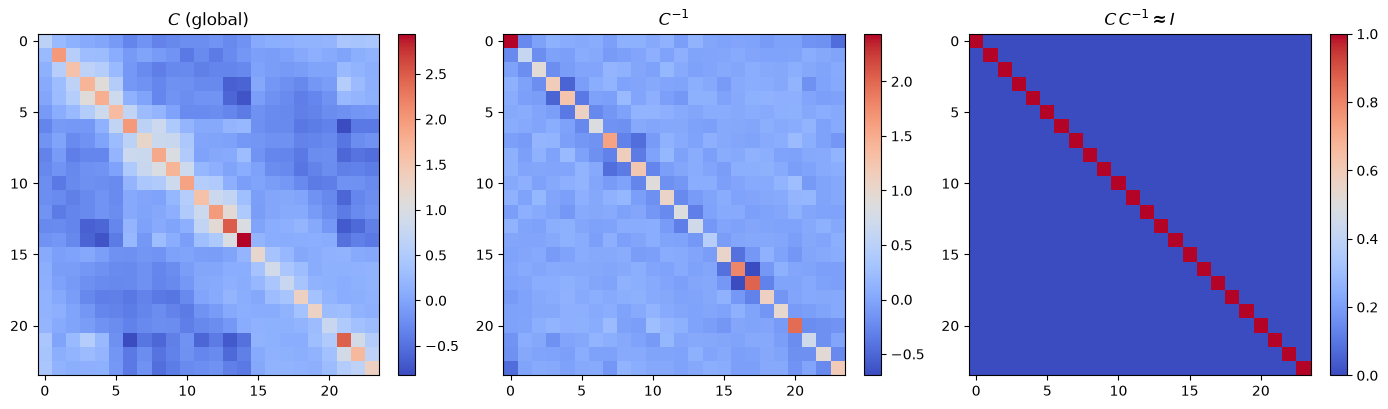

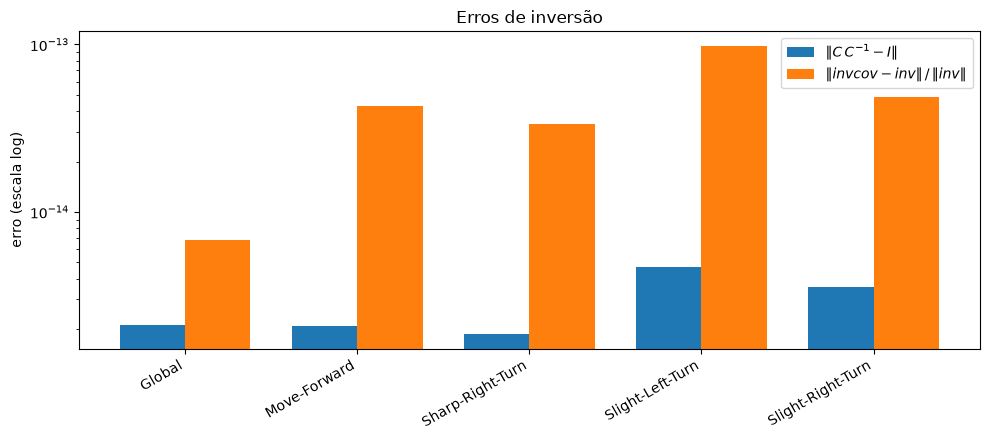

In [6]:
import matplotlib.pyplot as plt

# heatmaps: C, C^-1 e C.C^-1 (global)
C, Cinv = covs["Global"], invs["Global"]
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, M, t in zip(axes, [C, Cinv, C @ Cinv],
                    [r"$C$ (global)", r"$C^{-1}$", r"$C\,C^{-1}\approx I$"]):
    im = ax.imshow(M, cmap="coolwarm")
    ax.set_title(t)
    fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

# erros de inversão por matriz
nomes = list(covs)
err_id = [np.linalg.norm(covs[n] @ invs[n] - I) for n in nomes]
err_svd = [np.linalg.norm(invs_svd[n] - invs[n]) / np.linalg.norm(invs[n]) for n in nomes]

x = np.arange(len(nomes)); w = 0.38
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(x - w/2, err_id, w, label=r"$\|C\,C^{-1}-I\|$")
ax.bar(x + w/2, err_svd, w, label=r"$\|invcov-inv\|\,/\,\|inv\|$")
ax.set_yscale("log")
ax.set_xticks(x); ax.set_xticklabels(nomes, rotation=30, ha="right")
ax.set_ylabel("erro (escala log)")
ax.set_title("Erros de inversão")
ax.legend()
plt.tight_layout()
plt.show()

### Verificação por classe

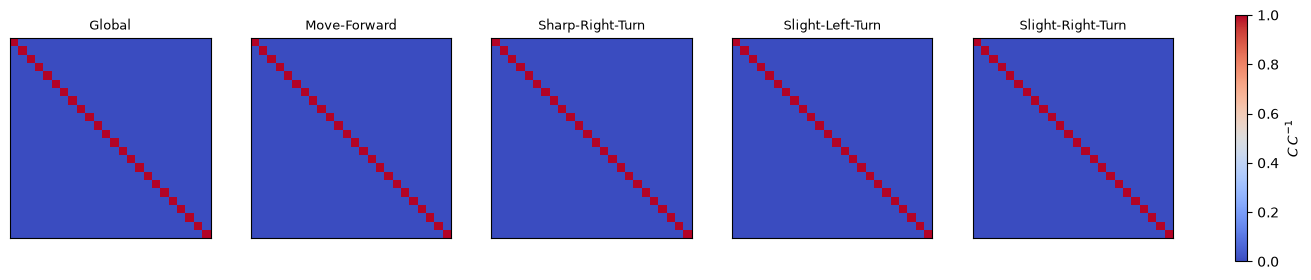

In [7]:
fig, axes = plt.subplots(1, len(nomes), figsize=(16, 3.2))
for ax, n in zip(axes, nomes):
    im = ax.imshow(covs[n] @ invs[n], cmap="coolwarm", vmin=0, vmax=1)
    ax.set_title(n, fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(im, ax=axes, fraction=0.012, label=r"$C\,C^{-1}$")
plt.show()